In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import Flatten
from keras. layers import MaxPooling2D
from keras.layers import Dense
import numpy as np
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.datasets import fashion_mnist

In [ ]:
# Download and load the Fashion-MNIST dataset
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Display dataset shapes
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [ ]:
# Normalize pixel values from [0, 255] to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [ ]:
# Add the channel dimension
# Before: (60000, 28, 28)
# After:  (60000, 28, 28, 1)

#Here, -1 means:Automatically determine the number of images in x_train.

#Since Fashion-MNIST has 60,000 training images, NumPy interprets it as:  -1 becomes 60000
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("CNN training input shape:", x_train.shape)
print("CNN testing input shape:", x_test.shape)

CNN training input shape: (60000, 28, 28, 1)
CNN testing input shape: (10000, 28, 28, 1)


In [ ]:
def create_cnn1():

    model = models.Sequential(name="CNN1")

    # Input layer
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution block
    model.add(layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))
    model.add(layers.MaxPooling2D(pool_size=(2, 2)))

    # Second convolution block
    model.add(layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))
    model.add(layers.MaxPooling2D(pool_size=(2, 2)))

    # Classification layers
    model.add(layers.Flatten())
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(0.4))

    # Fashion-MNIST has 10 classes
    model.add(layers.Dense(10, activation="softmax"))

    return model

In [ ]:
def create_cnn2():

    model = models.Sequential(name="CNN2")

    # Input layer
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution block
    model.add(layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))

    model.add(layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))

    model.add(layers.MaxPooling2D(
        pool_size=(2, 2)
    ))

    model.add(layers.Dropout(0.25))

    # Second convolution block
    model.add(layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))

    model.add(layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))

    model.add(layers.MaxPooling2D(
        pool_size=(2, 2)
    ))

    model.add(layers.Dropout(0.25))

    # Flatten layer
    model.add(layers.Flatten())

    # Fully connected layer
    model.add(layers.Dense(
        128,
        activation="relu"
    ))

    model.add(layers.Dropout(0.5))

    # Output layer
    model.add(layers.Dense(
        10,
        activation="softmax"
    ))

    return model

In [ ]:
def create_cnn3():

    model = models.Sequential(name="CNN3")

    # Input layer
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution block
    # Larger 5 × 5 kernel
    model.add(layers.Conv2D(
        filters=32,
        kernel_size=(5, 5),
        activation="relu",
        padding="same"
    ))
    model.add(layers.MaxPooling2D(pool_size=(2, 2)))
    model.add(layers.Dropout(0.2))

    # Second convolution block
    model.add(layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))
    model.add(layers.MaxPooling2D(pool_size=(2, 2)))
    model.add(layers.Dropout(0.3))

    # Third convolution block
    model.add(layers.Conv2D(
        filters=128,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ))

    # Reduces each feature map to one value
    model.add(layers.GlobalAveragePooling2D())

    # Classification layers
    model.add(layers.Dense(128, activation="relu"))
    model.add(layers.Dropout(0.5))

    model.add(layers.Dense(10, activation="softmax"))

    return model

In [ ]:
cnn1 = create_cnn1()
cnn2 = create_cnn2()
cnn3 = create_cnn3()

In [ ]:
from tensorflow.keras.optimizers import Adam
cnn1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Create the ImageDataGenerator for data augmentation
train_datagen = ImageDataGenerator(
    rotation_range=10,          # Randomly rotate images up to 10 degrees
    width_shift_range=0.1,      # Random horizontal shift
    height_shift_range=0.1,     # Random vertical shift
    zoom_range=0.1,             # Random zoom
    shear_range=0.1,            # Random shear transformation
    fill_mode="nearest"
)

# Test images should not be augmented
test_datagen = ImageDataGenerator()

batch_size = 32
train_generator1 = train_datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=True
)

train_generator2 = train_datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=True
)

train_generator3 = train_datagen.flow(
    x_train,
    y_train,
    batch_size=batch_size,
    shuffle=True
)
test_generator = test_datagen.flow(
    x_test,
    y_test,
    batch_size=batch_size,
    shuffle=False   #During testing, the order should remain unchanged.
)

train_generator1 → x_train, y_train

train_generator2 → x_train, y_train

train_generator3 → x_train, y_train

The difference is that each generator independently performs:

1.   Random shuffling;
2.   Random augmentation;
3.   Batch creation.

So CNN1, CNN2 and CNN3 may see the same original image with different transformations and in a different order.

In [ ]:
history_cnn1 = cnn1.fit(
    train_generator1,
    epochs=5,
    validation_data=test_generator
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 17ms/step - accuracy: 0.7408 - loss: 0.6914 - val_accuracy: 0.8229 - val_loss: 0.4545
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.8065 - loss: 0.5189 - val_accuracy: 0.8652 - val_loss: 0.3735
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 15ms/step - accuracy: 0.8313 - loss: 0.4543 - val_accuracy: 0.8742 - val_loss: 0.3383
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8432 - loss: 0.4207 - val_accuracy: 0.8853 - val_loss: 0.3117
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 14ms/step - accuracy: 0.8556 - loss: 0.3898 - val_accuracy: 0.8869 - val_loss: 0.3046


In [ ]:
history_cnn2 = cnn2.fit(
    train_generator2,
    epochs=5,
    validation_data=test_generator
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 16ms/step - accuracy: 0.7360 - loss: 0.7019 - val_accuracy: 0.8224 - val_loss: 0.4380
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.8113 - loss: 0.5050 - val_accuracy: 0.8765 - val_loss: 0.3397
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - accuracy: 0.8402 - loss: 0.4343 - val_accuracy: 0.8872 - val_loss: 0.3040
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.8539 - loss: 0.4007 - val_accuracy: 0.8945 - val_loss: 0.2903
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 16ms/step - accuracy: 0.8609 - loss: 0.3786 - val_accuracy: 0.8906 - val_loss: 0.2916


In [ ]:
history_cnn3 = cnn3.fit(
    train_generator3,
    epochs=5,
    validation_data=test_generator
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 40s 18ms/step - accuracy: 0.6389 - loss: 0.9545 - val_accuracy: 0.7431 - val_loss: 0.6317
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - accuracy: 0.7529 - loss: 0.6574 - val_accuracy: 0.7858 - val_loss: 0.5348
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 29s 15ms/step - accuracy: 0.7795 - loss: 0.5835 - val_accuracy: 0.8007 - val_loss: 0.4993
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.7982 - loss: 0.5395 - val_accuracy: 0.8437 - val_loss: 0.4285
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.8135 - loss: 0.4986 - val_accuracy: 0.8338 - val_loss: 0.4413


In [ ]:
from tensorflow.keras.layers import Input, Concatenate

input_shape = (28, 28, 1)
stack_input = Input(shape=input_shape)

# Get softmax outputs from each base model
pred1 = cnn1(stack_input)
pred2 = cnn2(stack_input)
pred3 = cnn3(stack_input)

# This creates a Concatenate layer object.Concatenate layer applied to [pred1, pred2, pred3]
merged = Concatenate()([pred1, pred2, pred3])

In [ ]:
# Hidden layer of the second-level MLP
x = Dense(16, activation="relu")(merged)

x = layers.Dropout(0.3)(x)

# Final output layer for 10 Fashion-MNIST classes
final_output = Dense(10, activation="softmax")(x)

This complete architecture:

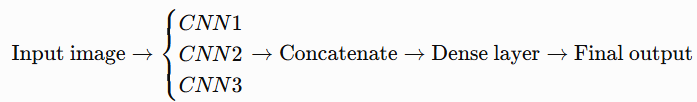

So models.Model() does not add a new computational layer. It packages the already connected layers into one trainable model.

In [ ]:
stacking_model = models.Model(
    inputs=stack_input,
    outputs=final_output
)

In [ ]:
cnn1.trainable = False
cnn2.trainable = False
cnn3.trainable = False

In [ ]:
stacking_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_stacking = stacking_model.fit(
    train_generator1,
    epochs=5,
    validation_data=test_generator
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.7832 - loss: 0.7241 - val_accuracy: 0.8976 - val_loss: 0.3104
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.8507 - loss: 0.4588 - val_accuracy: 0.8994 - val_loss: 0.3074
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 15ms/step - accuracy: 0.8573 - loss: 0.4429 - val_accuracy: 0.9007 - val_loss: 0.3040
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.8596 - loss: 0.4330 - val_accuracy: 0.9015 - val_loss: 0.3031
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.8617 - loss: 0.4245 - val_accuracy: 0.9006 - val_loss: 0.3025


In [ ]:
stacking_loss, stacking_accuracy = stacking_model.evaluate(
    test_generator
)

print("Stacking Accuracy:", stacking_accuracy)
print("Stacking Loss:", stacking_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9006 - loss: 0.3025
Stacking Accuracy: 0.900600016117096
Stacking Loss: 0.30250829458236694
